# DAY4 실습 01 — 일원분산분석(ANOVA)

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

## 데이터와 질문

데이터 파일 : `Steel_industry_data.csv`
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

한 철강 공장의 2018년 전력 사용 기록이다. 15분마다 1건씩 기록되어 있다.

| 열 | 뜻 |
|---|---|
| `date` | 기록 시각 (일/월/연 시:분) |
| `Usage_kWh` | 15분 동안의 전력 사용량 (kWh) |
| `WeekStatus` | 평일(Weekday) · 주말(Weekend) |
| `Day_of_week` | 요일 (Monday ~ Sunday) |

**질문** : 평일 하루 전력 사용량의 평균은 6월 · 10월 · 11월에 같은가?

**실습 전제** : 하루를 대상 하나로 보고, 각 월의 평일 하루 사용량을 그 달의 표본으로 쓴다. 여기서는 날짜별 관측값이 서로 독립이라고 가정한다. 실제 분석에서는 시간에 따른 의존성도 확인한다.

In [ ]:
# 데이터 확인 : 행·열 수, 사용량 결측, 평일·주말 기록 수
print("행·열:", data.shape)                               # shape : (행 수, 열 수)
print("사용량 결측:", data["Usage_kWh"].isna().sum())      # isna : 빈 값이면 True. 모두 더하면 빈 값(결측)의 개수
print(data["WeekStatus"].value_counts())                 # value_counts : 값마다 몇 건인지 센다

행·열: (35040, 11)
사용량 결측: 0
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64


## 1. 검정 선택

검정은 결과변수의 유형과 비교 구조로 고른다.

| 결과변수 | 비교 구조 | 검정 |
|---|---|---|
| 수치형 (평균) | 한 집단 vs 기준값 | 일표본 t검정 |
| 수치형 (평균) | 같은 대상의 전·후 | 대응표본 t검정 |
| 수치형 (평균) | 독립된 두 집단 | Welch t검정 |
| 수치형 (평균) | 독립된 세 집단 이상 | **일원분산분석(ANOVA)** |
| 범주형 (비율) | 한 집단 비율 vs 기준 비율 | **정확 이항검정** |
| 범주형 (비율) | 독립된 두 집단의 비율 | **2×2 카이제곱 검정** |
| 범주형 (분포) | 한 범주형 변수 vs 기준 비율 | **카이제곱 적합도 검정** |
| 범주형 (분포) | 여러 집단의 비율 | **카이제곱 동질성 검정** |
| 범주형 × 범주형 | 두 변수의 관련성 | **카이제곱 독립성 검정** |


공식 문서 : [scipy.stats 검정 함수 목록](https://docs.scipy.org/doc/scipy/reference/stats.html#hypothesis-tests-and-related-functions)

## 2. 일원분산분석(ANOVA)

일원분산분석(ANOVA)은 집단을 나누는 기준이 하나일 때 세 집단 이상의 모평균이 같은지 검정하는 방법이다. 평균을 비교하지만 판단 재료로 분산을 쓰기 때문에 분산분석(Analysis of Variance)이라고 부른다. **일원**은 집단을 나누는 기준이 하나라는 뜻이다.

**t검정을 둘씩 반복하지 않는 이유** : 세 집단을 t검정으로 둘씩 비교하면 비교가 3번이다. 여러 번 검정하면 적어도 한 번 잘못 기각할 위험이 커진다. 일원분산분석은 세 집단을 한 번에 비교한다.

**가설 형식**

- 귀무가설(H₀): 모든 집단의 모평균이 같다. (μ₁ = μ₂ = μ₃)
- 대립가설(H₁): 적어도 한 집단의 모평균이 다르다. (적어도 한 μᵢ가 다르다)

대립가설은 "모두 다르다"가 아니다. 한 집단만 달라도 대립가설에 해당한다.

**검정통계량 F** : F = 집단 간 분산 ÷ 집단 내 분산. 집단 평균끼리의 차이가 집단 안의 흩어짐보다 클수록 F가 커지고 p값이 작아진다.

**확인할 가정**

| 가정 | 뜻 | 확인 방법 |
|---|---|---|
| 독립성 | 관측값끼리 서로 영향을 주지 않는다 | 검정 함수가 없다. 자료를 모은 방법으로 판단한다 |
| 정규성 | 각 집단의 값이 종 모양에서 크게 벗어나지 않는다 | 집단별 히스토그램과 `stats.shapiro` |
| 등분산성 | 집단마다 퍼진 정도가 비슷하다 | 집단별 표준편차와 `stats.levene` |

| 함수 | 기능 |
|---|---|
| `pd.DataFrame({"A": A, "B": B, "C": C}).agg(["mean", "std"])` | 집단별 평균과 표준편차(표본표준편차)를 표 하나로 구한다 |
| `stats.f_oneway(A, B, C)` | 일원분산분석. `.statistic`(F)과 `.pvalue` |
| `stats.levene(A, B, C)` | 등분산 검정. 귀무가설(H₀): 모든 집단의 모분산이 같다. (σ₁² = σ₂² = σ₃²) |

공식 문서 : [scipy.stats.f_oneway](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html) · [scipy.stats.levene](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html)

In [ ]:
# [예제] 포장 라인 A · B · C 에서 박스 1개 처리시간(초)을 8번씩 측정해 세 라인의 평균을 비교한다
# 귀무가설(H₀): 세 라인의 모평균 처리시간은 같다. (μA = μB = μC)
# 대립가설(H₁): 적어도 한 라인의 모평균 처리시간이 다르다. (적어도 한 μ가 다르다)
# 유의수준 α = 0.05
A = [30.5, 27.9, 31.5, 29.7, 32.6, 30.9, 28.9, 32.0]   # 라인 A 처리시간 8회
B = [32.6, 30.8, 29.0, 33.3, 31.6, 33.7, 32.0, 30.0]   # 라인 B 처리시간 8회
C = [31.3, 34.4, 32.7, 30.3, 33.3, 32.1, 35.0, 33.9]   # 라인 C 처리시간 8회

# 1) 기술통계 : 세 라인을 열로 묶은 표로 평균 · 표준편차를 한 번에 본다
line_df = pd.DataFrame({"A": A, "B": B, "C": C})     # 세 라인을 열로 묶은 표 (8행 × 3열)
print(line_df.agg(["mean", "std"]).round(2))

# 2) 조건 확인 : 정규성(라인별) · 등분산
print("Shapiro p A · B · C:", round(stats.shapiro(A).pvalue, 3), round(stats.shapiro(B).pvalue, 3), round(stats.shapiro(C).pvalue, 3))
#   shapiro(값).pvalue : 정규성 검정 결과에서 p값만 꺼낸다. 라인마다 따로 검정한다
print("Levene p:", round(stats.levene(A, B, C).pvalue, 3))   # levene 에는 세 라인을 한꺼번에 넣는다

# 3) 일원분산분석
line_result = stats.f_oneway(A, B, C)                  # 비교할 집단을 쉼표로 나눠 넣는다
print("F:", round(line_result.statistic, 2), "/ p값:", round(line_result.pvalue, 4))   # .statistic = F 값, .pvalue = p값

# [결과]
# - 평균 A 30.5초, B 31.62초, C 32.88초. 표준편차는 1.59 ~ 1.62초로 비슷하다
# - Shapiro p 0.89 ~ 0.95, Levene p = 0.998 → 정규성과 등분산이 크게 어긋나지 않으므로 일원분산분석을 쓴다
# - F = 4.39, p = 0.0255
# - 통계적 결론 : p = 0.0255 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 세 라인의 모평균 처리시간이 모두 같다고 보기 어렵다. 표본 평균은 A 30.5초, C 32.88초로 최대 2.38초 차이가 났다 (라인별 8회)

          A      B      C
mean  30.50  31.62  32.88
std    1.59   1.62   1.60
Shapiro p A · B · C: 0.93 0.894 0.951
Levene p: 0.998
F: 4.39 / p값: 0.0255


## 3. 사후검정 : Tukey HSD

**사후검정**은 분산분석에서 귀무가설을 기각한 뒤, 어느 집단끼리 차이가 있는지 둘씩 비교하는 검정이다. **Tukey HSD**는 여러 쌍을 한꺼번에 비교해도 잘못 기각할 위험이 유의수준을 넘지 않도록 p값을 조정한다(**조정 p값**).


- 귀무가설(H₀): 두 집단의 모평균이 같다. (예 : μA = μC)
- 대립가설(H₁): 두 집단의 모평균이 다르다. (예 : μA ≠ μC)

Tukey HSD는 두 가지 함수로 할 수 있다. 결과는 같고 표 모양만 다르다.

| 함수 | 기능 |
|---|---|
| `pairwise_tukeyhsd(값, 집단이름)` | 방법 1 (statsmodels). 쌍마다 한 줄로 집단 이름 · 평균 차이 · 조정 p값 · 기각 여부를 보여 준다 |
| `stats.tukey_hsd(A, B, C)` | 방법 2 (scipy). 집단을 넣은 순서대로 0, 1, 2번으로 표시한다 |
| `결과.pvalue[0, 2]` | 방법 2에서 0번과 2번 집단 쌍의 조정 p값 |

**방법 1 (`pairwise_tukeyhsd`) 결과표 읽는 법** (한 줄 = 한 쌍)


```
Multiple Comparison of Means - Tukey HSD, FWER=0.05
===================================================
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B    1.125 0.3574 -0.8961 3.1461  False
     A      C    2.375 0.0195  0.3539 4.3961   True
     B      C     1.25  0.285 -0.7711 3.2711  False
---------------------------------------------------
```

| 열 | 뜻 | 읽는 법 |
|---|---|---|
| `FWER=0.05` | 유의수준 (`alpha=0.05`, 기본값) | 세 쌍을 한꺼번에 비교해도 잘못 기각할 위험이 전체 5%를 넘지 않도록 맞춘 유의수준이다 |
| `group1`, `group2` | 비교한 두 집단 | |
| `meandiff` | group2 평균 − group1 평균 | 양수면 group2가 더 크다 |
| `p-adj` | 조정 p값 | 0.05보다 작으면 두 집단의 평균이 다르다고 본다 |
| `lower`, `upper` | 평균 차이의 95% 신뢰구간 | 0이 들어 있지 않으면 차이가 있다 |
| `reject` | 귀무가설 기각 여부 | True = 차이가 있다, False = 차이가 있다고 볼 근거가 부족하다 |

**방법 2 (`stats.tukey_hsd`) 결과표 읽는 법** (같은 쌍이 두 번 나오므로 실제로 볼 줄은 (0 - 1), (0 - 2), (1 - 2) 세 줄)

 0번 = A, 1번 = B, 2번 = C 다.

```
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -1.125     0.357    -3.146     0.896
 (0 - 2)     -2.375     0.020    -4.396    -0.354
 (1 - 0)      1.125     0.357    -0.896     3.146
 (1 - 2)     -1.250     0.285    -3.271     0.771
 (2 - 0)      2.375     0.020     0.354     4.396
 (2 - 1)      1.250     0.285    -0.771     3.271
```

| 열 | 뜻 | 읽는 법 |
|---|---|---|
| `Comparison` | 비교한 쌍 | (0 - 2)는 0번 집단과 2번 집단의 비교다 |
| `Statistic` | 앞 집단 평균 − 뒤 집단 평균 | 음수면 뒤 집단이 더 크다. 같은 쌍이 (2 - 0)으로 한 번 더 나오고 부호만 반대다 |
| `p-value` | 조정 p값 | 0.05보다 작으면 두 집단의 평균이 다르다고 본다 |
| `Lower CI`, `Upper CI` | 평균 차이의 95% 신뢰구간 | 0이 들어 있지 않으면 차이가 있다 |

공식 문서 : [statsmodels pairwise_tukeyhsd](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html) · [scipy.stats.tukey_hsd](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html)

In [ ]:
# [예제] 방법 1 : statsmodels 의 pairwise_tukeyhsd 로 포장 라인 A · B · C 를 둘씩 비교한다
# 쌍마다 귀무가설(H₀): 두 라인의 모평균 처리시간은 같다. (예 : μA = μC)
# 쌍마다 대립가설(H₁): 두 라인의 모평균 처리시간은 다르다. (예 : μA ≠ μC)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

#   from 모듈 import 함수 : statsmodels 라이브러리에서 이 함수만 불러온다

values = A + B + C
#   목록끼리 + 는 숫자 덧셈이 아니라 이어 붙이기다 → A 8개, B 8개, C 8개가 차례로 이어진 24개 값
groups = ["A"] * 8 + ["B"] * 8 + ["C"] * 8
#   ["A"] * 8 : "A" 를 8개 복사한 목록. 셋을 이어 붙이면 values 의 값마다 어느 라인인지 알려 주는 이름표 24개가 된다
print(pairwise_tukeyhsd(values, groups))
#   (값 목록, 이름표 목록) 순서로 넣는다. 두 목록의 길이(24)가 같아야 한다. meandiff 는 group2 평균 − group1 평균

# [결과]
# - A · B 줄 : B가 A보다 평균 1.125초 길다. p-adj 0.3574 ≥ 0.05, reject False → 차이가 있다고 볼 근거가 부족하다
# - A · C 줄 : C가 A보다 평균 2.375초 길다. p-adj 0.0195 < 0.05, 신뢰구간 0.35 ~ 4.40 에 0 이 없다, reject True → 차이가 있다
# - B · C 줄 : C가 B보다 평균 1.25초 길다. p-adj 0.285 ≥ 0.05, reject False → 차이가 있다고 볼 근거가 부족하다
# - 통계적 결론 : A · C 쌍만 조정 p = 0.0195 < 0.05 이므로 귀무가설을 기각한다. 나머지 두 쌍은 기각하지 못한다
# - 사실적 결론 : 세 라인 중 A와 C의 모평균 처리시간만 다르다고 볼 통계적 근거가 있다. 표본에서 C가 A보다 평균 2.375초 길었다

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B    1.125 0.3574 -0.8961 3.1461  False
     A      C    2.375 0.0195  0.3539 4.3961   True
     B      C     1.25  0.285 -0.7711 3.2711  False
---------------------------------------------------


In [ ]:
# [예제] 방법 2 : scipy 의 stats.tukey_hsd 로 같은 비교를 한다 (0번 = A, 1번 = B, 2번 = C)
# 쌍마다 귀무가설(H₀): 두 라인의 모평균 처리시간은 같다. (예 : μA = μC)
# 쌍마다 대립가설(H₁): 두 라인의 모평균 처리시간은 다르다. (예 : μA ≠ μC)
tukey = stats.tukey_hsd(A, B, C)          # 넣은 순서대로 0 = A, 1 = B, 2 = C
print(tukey)                              # Statistic 은 앞 집단 평균 − 뒤 집단 평균

print("A − B 조정 p값:", round(tukey.pvalue[0, 1], 3))   # pvalue[행 번호, 열 번호] : 0번(A)과 1번(B) 쌍의 조정 p값
print("A − C 조정 p값:", round(tukey.pvalue[0, 2], 3))   # 0번(A)과 2번(C) 쌍
print("B − C 조정 p값:", round(tukey.pvalue[1, 2], 3))   # 1번(B)과 2번(C) 쌍

# [결과]
# - Statistic 은 "앞 − 뒤"라 음수가 나온다. 음수는 뒤 집단이 더 크다는 뜻이므로 뒤집어 읽는다
# - (0 - 1) 줄 : −1.125 → B가 A보다 평균 1.125초 길다. 조정 p = 0.357 ≥ 0.05 → 차이가 있다고 볼 근거가 부족하다
# - (0 - 2) 줄 : −2.375 → C가 A보다 평균 2.375초 길다. 조정 p = 0.020 < 0.05, 신뢰구간 −4.40 ~ −0.35 에 0 이 없다 → 차이가 있다
# - (1 - 2) 줄 : −1.250 → C가 B보다 평균 1.25초 길다. 조정 p = 0.285 ≥ 0.05 → 차이가 있다고 볼 근거가 부족하다
# - 통계적 결론 : A · C 쌍만 조정 p = 0.020 < 0.05 이므로 귀무가설을 기각한다. 나머지 두 쌍은 기각하지 못한다
# - 사실적 결론 : 방법 1과 같다. A와 C의 모평균 처리시간만 다르다고 볼 통계적 근거가 있고, 표본에서 C가 A보다 평균 2.375초 길었다

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -1.125     0.357    -3.146     0.896
 (0 - 2)     -2.375     0.020    -4.396    -0.354
 (1 - 0)      1.125     0.357    -0.896     3.146
 (1 - 2)     -1.250     0.285    -3.271     0.771
 (2 - 0)      2.375     0.020     0.354     4.396
 (2 - 1)      1.250     0.285    -0.771     3.271

A − B 조정 p값: 0.357
A − C 조정 p값: 0.02
B − C 조정 p값: 0.285


## 4. 실습 : 월별 평일 하루 사용량

6월 · 10월 · 11월의 평일 하루 전력 사용량을 4단계로 비교한다.

1) 가설 설정
   - 귀무가설(H₀): 6월 · 10월 · 11월의 평일 하루 전력 사용량 모평균은 같다. (μ₆ = μ₁₀ = μ₁₁)
   - 대립가설(H₁): 적어도 한 달의 평일 하루 전력 사용량 모평균이 다르다. (적어도 한 μ가 다르다)
2) 유의수준 : α = 0.05
3) 조건 확인 → 검정 : 월별 정규성(히스토그램 · Shapiro) · 등분산(표준편차 · Levene) → `stats.f_oneway`
4) 결과 도출 : 기각하면 Tukey HSD로 어느 달끼리 다른지 확인하고 두 줄 결론을 쓴다

공식 문서 : [scipy.stats.f_oneway](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html) · [statsmodels pairwise_tukeyhsd](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html) · [scipy.stats.tukey_hsd](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html)

In [ ]:
# [예제] 평일 날짜별 하루 사용량 표를 만들고 6월 · 10월 · 11월 을 꺼낸다

# 1) 글자로 된 날짜를 날짜 · 시각 값으로 바꾼다
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y %H:%M")
#   to_datetime : "01/01/2018 00:15" 같은 글자를 날짜 · 시각 값으로 바꾼다
#   format : 글자의 모양을 알려 준다. %d 일 / %m 월 / %Y 연도 4자리 / %H 시 / %M 분
data["day"] = data["date"].dt.date              # .dt.date : 시각을 빼고 날짜만 남긴다 (2018-01-01)
data["month"] = data["date"].dt.month           # .dt.month : 월 숫자만 남긴다 (1 ~ 12)

# 2) 평일 기록만 남기고 날짜별 하루 사용량을 만든다
weekday = data.loc[data["WeekStatus"] == "Weekday"]
daily = weekday.groupby(["day", "month"])["Usage_kWh"].sum().reset_index()

print(daily.head(3))

# 3) 월별 하루 사용량을 꺼낸다
jun = daily.loc[daily["month"] == 6, "Usage_kWh"]       # loc[행 조건, 열 이름] : 6월 행의 하루 사용량 열만
octo = daily.loc[daily["month"] == 10, "Usage_kWh"]     # 10월
nov = daily.loc[daily["month"] == 11, "Usage_kWh"]      # 11월
print("평일 일수 6월 · 10월 · 11월:", len(jun), len(octo), len(nov))   # len : 개수 = 평일 일수

# [결과]
# - daily 는 한 행이 평일 하루다 (날짜 · 월 · 하루 사용량)
# - 평일 일수는 6월 21일, 10월 23일, 11월 22일이다. 집단마다 표본 크기가 달라도 일원분산분석을 쓸 수 있다

          day  month  Usage_kWh
0  2018-01-01      1     351.86
1  2018-01-02      1    3950.43
2  2018-01-03      1    3561.05
평일 일수 6월 · 10월 · 11월: 21 23 22


In [ ]:
# [실습]
# 상황 : 세 달의 평균을 비교하기 전에 조건을 확인한다.
#        귀무가설(H₀): 각 달의 하루 사용량은 정규분포를 따른다. / 대립가설(H₁): 정규분포를 따르지 않는다.
#        귀무가설(H₀): 세 달의 하루 사용량 모분산은 같다. (σ₆² = σ₁₀² = σ₁₁²) / 대립가설(H₁): 적어도 한 달의 모분산이 다르다.
# 세 달의 히스토그램을 1행 3열로 그리고, 달별 평균 · 표준편차 · Shapiro-Wilk p값과 Levene p값을 구하시오.



In [ ]:
# [실습]
# 상황 : 조건이 크게 어긋나지 않으므로 일원분산분석으로 세 달의 평균을 비교한다.
#        귀무가설(H₀): 6월 · 10월 · 11월의 평일 하루 전력 사용량 모평균은 같다. (μ₆ = μ₁₀ = μ₁₁)
#        대립가설(H₁): 적어도 한 달의 평일 하루 전력 사용량 모평균이 다르다. (적어도 한 μ가 다르다)
#        유의수준 α = 0.05
# 일원분산분석의 F와 p값을 구하고 통계적 결론을 쓰시오.



In [ ]:
# [실습]
# 상황 : 어느 달끼리 평균이 다른지 확인한다. (0번 = 6월, 1번 = 10월, 2번 = 11월)
#        쌍마다 귀무가설(H₀): 두 달의 모평균은 같다. (예 : μ₆ = μ₁₁) / 대립가설(H₁): 두 달의 모평균은 다르다. (예 : μ₆ ≠ μ₁₁)
# 방법 2(stats.tukey_hsd)로 Tukey HSD 결과를 출력하고, 세 쌍의 조정 p값을 구해 차이가 있는 쌍을 찾으시오.



In [ ]:
# [실습]
# 상황 : 위 결과를 보고서에 두 줄로 정리한다.
# 아래 결론 문장의 빈칸을 채우시오.
#    통계적 결론 : 일원분산분석 p = ___ ___ 0.05 이므로 귀무가설을 ___________.
#    사실적 결론 : 세 달의 평일 하루 전력 사용량 모평균이 모두 같다고 보기 어렵다. Tukey HSD 결과 ___월과 ___월만 차이가 있다고 볼 통계적 근거가 있으며, 표본에서 ___월이 ___월보다 평균 ______ kWh 많았다 (평일 6월 21일 · 10월 23일 · 11월 22일).



## 5. 참고 : 집단별 분산이 뚜렷이 다를 때 — Welch ANOVA와 Games-Howell

두 집단에서 Welch t검정을 쓴 것처럼, 세 집단 이상에서도 집단별 분산이 뚜렷이 다르면 등분산을 가정하지 않는 방법을 쓴다.

| 상황 | 평균 비교 | 사후검정 |
|---|---|---|
| 분산이 비슷하다 | 일원분산분석 `stats.f_oneway(A, B, C)` | Tukey HSD `stats.tukey_hsd(A, B, C)` |
| 분산이 뚜렷이 다르다 | Welch ANOVA `stats.f_oneway(A, B, C, equal_var=False)` | Games-Howell `stats.tukey_hsd(A, B, C, equal_var=False)` |



공식 문서 : [scipy.stats.f_oneway (equal_var)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html) · [scipy.stats.tukey_hsd (equal_var)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html)

In [ ]:
# [예제] 참고 : 같은 포장 라인 자료로 일원분산분석과 Welch ANOVA, Tukey HSD 와 Games-Howell 을 비교한다
import scipy                                               # 버전을 확인하려고 scipy 전체를 불러온다
print("SciPy 버전:", scipy.__version__)                     # __version__ : 설치된 버전. 1.16.0 이상이어야 equal_var 를 쓸 수 있다

standard = stats.f_oneway(A, B, C)                         # 일원분산분석 : 등분산 가정
welch = stats.f_oneway(A, B, C, equal_var=False)           # Welch ANOVA : equal_var=False 는 "분산이 같다고 가정하지 않는다"는 뜻
print("일원분산분석 → F:", round(standard.statistic, 2), "/ p값:", round(standard.pvalue, 4))
print("Welch ANOVA → F:", round(welch.statistic, 2), "/ p값:", round(welch.pvalue, 4))

games = stats.tukey_hsd(A, B, C, equal_var=False)          # Games-Howell : 등분산 가정 없는 사후검정
print("A − C 조정 p값 → Tukey:", round(tukey.pvalue[0, 2], 3), "/ Games-Howell:", round(games.pvalue[0, 2], 3))

# [결과]
# - 일원분산분석 p = 0.0255, Welch ANOVA p = 0.0364 → 두 방법 모두 귀무가설을 기각한다
# - A − C 조정 p값 Tukey 0.020, Games-Howell 0.025 → 두 방법 모두 A와 C만 다르다고 판단한다


SciPy 버전: 1.18.1
일원분산분석 → F: 4.39 / p값: 0.0255
Welch ANOVA → F: 4.24 / p값: 0.0364
A − C 조정 p값 → Tukey: 0.02 / Games-Howell: 0.025


## 6. 비모수 검정 : Kruskal-Wallis 검정

독립된 세 집단 이상의 자료가 정규분포에서 크게 벗어나고, 순위를 이용해 집단 간 분포 차이를 비교하려는 경우 Kruskal–Wallis 검정을 고려할 수 있다. 독립된 세 집단 이상의 값을 한꺼번에 순위로 바꿔, 어느 집단의 순위가 높게 몰리는지를 본다. 두 집단에서 쓴 Mann-Whitney U 검정을 세 집단 이상으로 넓힌 검정이다.

| 항목 | 내용 |
|---|---|
| 가설 형식 | 귀무가설(H₀): 모든 집단의 분포는 같다. (F₁ = F₂ = F₃)<br>대립가설(H₁): 적어도 한 집단의 분포가 다르다. (적어도 한 Fᵢ가 다르다) |
| 결과 해석 | 평균의 동일성을 직접 검정하지 않는다. 어느 집단의 값이 더 크게 나오는 경향인지와 집단별 중앙값으로 결론을 쓴다 |

F₁, F₂, F₃는 각 집단 값의 분포를 나타내는 기호다.

| 함수 | 기능 |
|---|---|
| `stats.kruskal(A, B, C)` | Kruskal-Wallis 검정. `.statistic`(H)과 `.pvalue` |

공식 문서 : [scipy.stats.kruskal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html)

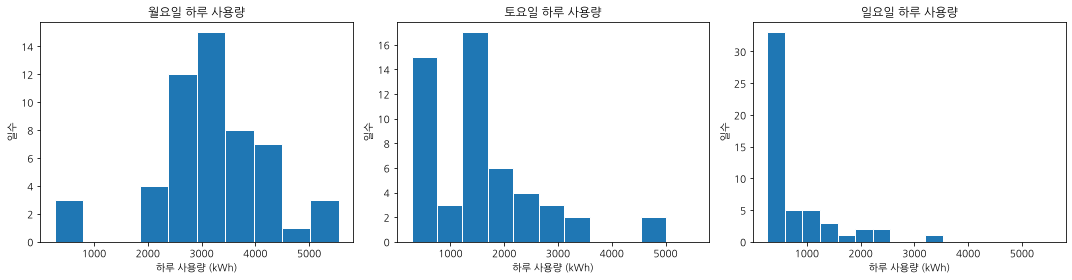

월요일 일수: 53 / 중앙값: 3147.2 / Shapiro p: 0.0083
토요일 일수: 52 / 중앙값: 1451.0 / Shapiro p: 0.0001
일요일 일수: 52 / 중앙값: 339.6 / Shapiro p: 0.0
H: 82.92 / p값: 9.889136871674908e-19


In [ ]:
# [예제] 월요일 · 토요일 · 일요일의 하루 전력 사용량 분포를 비교한다
# 귀무가설(H₀): 월요일 · 토요일 · 일요일 하루 전력 사용량의 분포는 같다. (F₁ = F₂ = F₃)
# 대립가설(H₁): 적어도 한 요일의 하루 전력 사용량 분포가 다르다. (적어도 한 Fᵢ가 다르다)
# 유의수준 α = 0.05
all_daily = data.groupby(["day", "Day_of_week"])["Usage_kWh"].sum().reset_index()
#   4절과 같은 방법으로 날짜별 하루 사용량을 만든다. 주말도 포함하고, 요일 열(Day_of_week)을 남긴다
mon = all_daily.loc[all_daily["Day_of_week"] == "Monday", "Usage_kWh"]
sat = all_daily.loc[all_daily["Day_of_week"] == "Saturday", "Usage_kWh"]
sun = all_daily.loc[all_daily["Day_of_week"] == "Sunday", "Usage_kWh"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, values, title in zip(axes, [mon, sat, sun], ["월요일", "토요일", "일요일"]):
    ax.hist(values, bins=10, edgecolor="white")              # 한쪽으로 치우쳤는지 확인
    ax.set(title=title + " 하루 사용량", xlabel="하루 사용량 (kWh)", ylabel="일수")
plt.tight_layout()
plt.show()

for name, values in zip(["월요일", "토요일", "일요일"], [mon, sat, sun]):
    print(name, "일수:", len(values), "/ 중앙값:", round(values.median(), 1), "/ Shapiro p:", round(stats.shapiro(values).pvalue, 4))   # median : 중앙값

kw_result = stats.kruskal(mon, sat, sun)                   # 세 요일을 쉼표로 나눠 넣는다
print("H:", round(kw_result.statistic, 2), "/ p값:", kw_result.pvalue)

# [결과]
# - 일요일은 대부분 낮고 일부 날만 높아 오른쪽 꼬리가 길다. Shapiro p 는 세 요일 모두 0.05 미만이다 → Kruskal-Wallis 검정을 쓴다
# - 중앙값 월요일 3,147.2 · 토요일 1,451.0 · 일요일 339.6 kWh. H = 82.92, p = 9.9e-19 (p < 0.001)
# - 통계적 결론 : p < 0.001 이므로 귀무가설을 기각한다
# - 사실적 결론 : 세 요일의 하루 전력 사용량 분포가 같다고 보기 어렵다. 표본에서 월요일 · 토요일 · 일요일 순으로 사용량이 크게 나오는 경향이 있다 (중앙값 3,147.2 · 1,451.0 · 339.6 kWh, 각 52 ~ 53일)

## 7. 정리 : 세 집단 이상 비교

| 단계 | 내용 |
|---|---|
| 1) 가설 | 귀무가설(H₀): 모든 집단의 모평균이 같다. (μ₁ = μ₂ = μ₃) / 대립가설(H₁): 적어도 한 집단의 모평균이 다르다 |
| 2) 유의수준 | α = 0.05 |
| 3) 조건 확인 → 검정 | 집단별 히스토그램 · Shapiro, 표준편차 · Levene → 아래 표에서 고른다 |
| 4) 결과 도출 | 기각하면 사후검정으로 어느 쌍이 다른지 확인하고, 통계적 결론과 사실적 결론을 쓴다 |

| 상황 | 검정 | 기각 후 사후검정 |
|---|---|---|
| 정규성 · 등분산이 크게 어긋나지 않는다 | 일원분산분석 `stats.f_oneway` | Tukey HSD `pairwise_tukeyhsd` 또는 `stats.tukey_hsd` |
| 정규성은 괜찮고 분산이 뚜렷이 다르다 | Welch ANOVA `stats.f_oneway(..., equal_var=False)` | Games-Howell `stats.tukey_hsd(..., equal_var=False)` |
| 분포가 크게 치우치거나 극단값이 많다 | Kruskal-Wallis `stats.kruskal` | — |

### 해석 시 유의점

| 항목 | 해석 기준 |
|---|---|
| 일원분산분석의 대립가설 | "적어도 한 집단이 다르다"이다. 어느 집단이 다른지는 사후검정으로 확인한다 |
| 기각하지 못했을 때 | 모든 평균이 같다고 입증한 것이 아니다. 사후검정을 하지 않는다 |
| Tukey HSD의 p값 | 여러 쌍을 비교한 것을 반영해 조정한 p값이다 |
| Levene 검정 | p값이 크다고 등분산이 증명되지는 않는다.  |
| Kruskal-Wallis 결론 | 평균이 아니라 분포를 비교한다. 어느 집단이 더 크게 나오는 경향인지와 중앙값으로 쓴다 |

공식 문서 : [scipy.stats.f_oneway](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html) · [statsmodels pairwise_tukeyhsd](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html) · [scipy.stats.tukey_hsd](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html) · [scipy.stats.kruskal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html)